In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np
%matplotlib inline

In [2]:
!wget -O 'laba1.csv' -q 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv'

In [3]:
!wget -O 'laba2.csv' -q 'https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv'

In [4]:
df1 = pd.read_csv("laba1.csv", encoding='UTF-8', sep=';')
df1.shape

(1599, 12)

In [5]:
df1['wine_type'] = 'red'

In [6]:
df2 = pd.read_csv("laba2.csv", encoding='UTF-8', sep=';')
df2.shape

(4898, 12)

In [7]:
df2['wine_type'] = 'white'

In [8]:
df = pd.concat([df1, df2], ignore_index=True)
df.shape

(6497, 13)

## Объединение датасетов

Исходные данные состоят из двух файлов:
- **laba1.csv** — 1599 образцов красного вина
- **laba2.csv** — 4898 образцов белого вина

Оба файла содержат одинаковый набор из 11 признаков(фичей) 
и целевую переменную `quality` (оценка качества вина от 0 до 10).

**Почему я объединила датасеты:**

1. **Одинаковая структура.** Оба файла имеют одинаковые колонки, 
   поэтому их можно корректно объединить.

2. **Больше данных.** Объединённый датасет содержит 6497 образцов — 
   это даст модели больше информации для обучения и повысит надёжность результатов.

3. **Новый признак.** Я добавила колонку `wine_type` (red/white), 
   чтобы модель могла учитывать различия между типами вина.

In [9]:
print(df.dtypes)

fixed acidity           float64
volatile acidity        float64
citric acid             float64
residual sugar          float64
chlorides               float64
free sulfur dioxide     float64
total sulfur dioxide    float64
density                 float64
pH                      float64
sulphates               float64
alcohol                 float64
quality                   int64
wine_type                object
dtype: object


In [10]:
print(df.isna().sum())

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
wine_type               0
dtype: int64


In [11]:
print(df.describe())

       fixed acidity  volatile acidity  citric acid  residual sugar  \
count    6497.000000       6497.000000  6497.000000     6497.000000   
mean        7.215307          0.339666     0.318633        5.443235   
std         1.296434          0.164636     0.145318        4.757804   
min         3.800000          0.080000     0.000000        0.600000   
25%         6.400000          0.230000     0.250000        1.800000   
50%         7.000000          0.290000     0.310000        3.000000   
75%         7.700000          0.400000     0.390000        8.100000   
max        15.900000          1.580000     1.660000       65.800000   

         chlorides  free sulfur dioxide  total sulfur dioxide      density  \
count  6497.000000          6497.000000           6497.000000  6497.000000   
mean      0.056034            30.525319            115.744574     0.994697   
std       0.035034            17.749400             56.521855     0.002999   
min       0.009000             1.000000         

## Первичный анализ данных

### Типы признаков

В датасете присутсвует единственный категориальный признак - `wine_type`. Все остальные признаки являются числовыми (`float64` или `int64`).

### Признаки, участвующие в анализе

| Признак | Описание |
|---------|----------|
| `fixed acidity` | Фиксированная кислотность (г/л) — содержание нелетучих кислот |
| `volatile acidity` | Летучая кислотность (г/л) — содержание уксусной кислоты |
| `citric acid` | Лимонная кислота (г/л) |
| `residual sugar` | Остаточный сахар (г/л) — сахар, оставшийся после ферментации |
| `chlorides` | Хлориды (г/л) — содержание соли |
| `free sulfur dioxide` | Свободный диоксид серы (мг/л) — антиоксидант и консервант |
| `total sulfur dioxide` | Общий диоксид серы (мг/л) — сумма свободного и связанного SO₂ |
| `density` | Плотность (г/см³) |
| `pH` | Кислотность/щелочность (шкала от 0 до 14) |
| `sulphates` | Сульфаты (г/л) — содержание сульфата калия |
| `alcohol` | Содержание алкоголя (% об.) |
| `wine_type` | Тип вина: красное (`red`) или белое (`white`) — добавленный признак |

**Целевая переменная:** `quality` — оценка качества вина дегустаторами (шкала от 0 до 10).

### Пропуски в данных

**Пропуски отсутствуют** — все 6497 образцов содержат полные значения по всем признакам. Это означает, что **не требуется заполнение пропусков**, и в дальнейшем мы сможем сразу перейти к корреляционному анализу и построению моделей.


In [12]:
df.quality.value_counts(normalize=True)\
        .sort_index() * 100

quality
3     0.461752
4     3.324611
5    32.907496
6    43.650916
7    16.607665
8     2.970602
9     0.076959
Name: proportion, dtype: float64

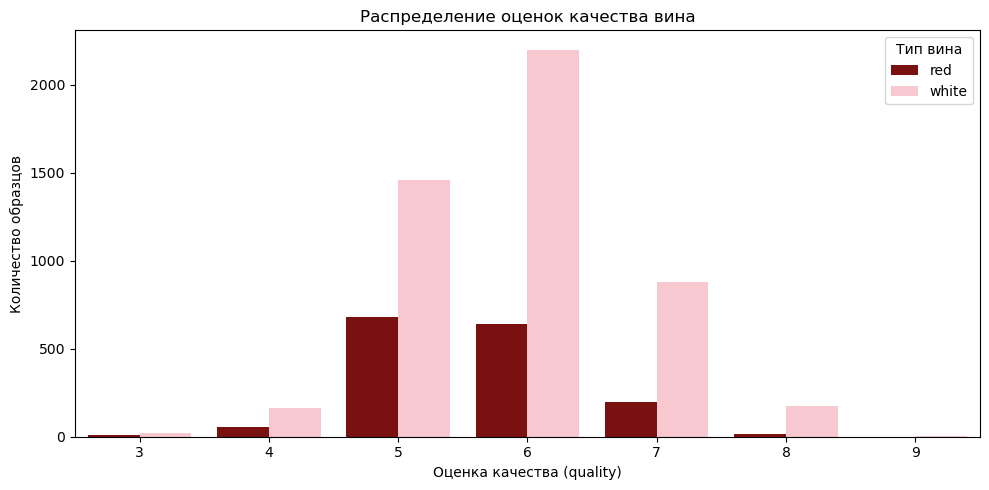

In [13]:
plt.figure(figsize=(10, 5))
sns.countplot(x='quality', data=df, hue='wine_type', palette={'red': 'darkred', 'white': 'pink'})
plt.title('Распределение оценок качества вина')
plt.xlabel('Оценка качества (quality)')
plt.ylabel('Количество образцов')
plt.legend(title='Тип вина')
plt.tight_layout()

### Распределение целевой переменной

Анализ распределения оценок качества (`quality`) показал следующее:

1. **Несбалансированное распределение.** Большинство образцов получили оценки **5** и **6**. Оценки 3, 4, 8 и 9 встречаются редко. Это может стать проблемой: модель будет хорошо предсказывать "средние" вина, но плохо — редкие (очень плохие или очень хорошие).

2. **Различия между типами вина.** Белое вино преобладает в выборке (4898 против 1599 образцов) и в среднем получает более высокие оценки: пик распределения белого вина — оценка 6, красного — оценка 5-6. Красное вино чаще получает низкие оценки (4-5).

3. **Признак `wine_type` потенциально важен.** Различия в распределении оценок между типами вина говорят о том, что тип вина может быть полезным признаком для модели. Однако это категориальный признак, и перед использованием в модели его необходимо закодировать.

4. **Диапазон оценок.** Оценки варьируются от 3 до 9. Оценок 0, 1, 2 и 10 в датасете нет.

/tmp/ipykernel_99489/3566959379.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=correlations.values, y=correlations.index, palette=colors)


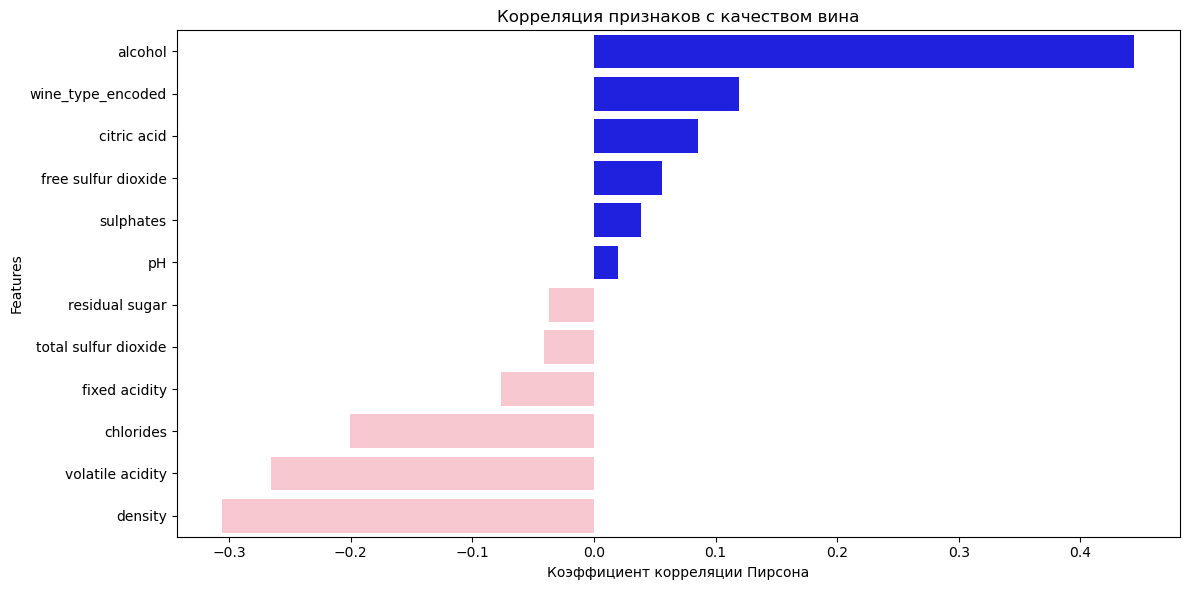

In [14]:
new_df = df.copy()
new_df['wine_type_encoded'] = new_df['wine_type'].apply(lambda x: 0 if x == 'red' else 1)
numeric_df = new_df.select_dtypes(include=[np.number])
correlations = numeric_df.corr()['quality'].drop('quality').sort_values(ascending=False)

plt.figure(figsize=(12, 6))
colors = ['blue' if x > 0 else 'pink' for x in correlations.values]
sns.barplot(x=correlations.values, y=correlations.index, palette=colors)
plt.title('Корреляция признаков с качеством вина')
plt.xlabel('Коэффициент корреляции Пирсона')
plt.ylabel('Features')
plt.tight_layout()

### Корреляционный анализ признаков с качеством вина

Анализ корреляций Пирсона показал, что ни один признак не имеет сильной линейной связи с качеством вина (все коэффициенты по модулю меньше 0.5). Это означает, что качество вина — комплексный показатель, определяемый совокупностью факторов, а не одним признаком.

**Топ-3 признака с наибольшей корреляцией (по модулю):**

1. **`alcohol` (≈ +0.44)** — самая сильная положительная корреляция. Более крепкие вина получают более высокие оценки. Это логично: высокое содержание алкоголя свидетельствует о зрелости винограда и полноценной ферментации.

2. **`density` (≈ −0.31)** — сильная отрицательная корреляция. Высокая плотность означает большее содержание воды и сахара, что характерно для менее зрелого винограда и менее качественных вин.

3. **`volatile acidity` (≈ −0.26)** — отрицательная корреляция. Летучая кислотность (уксусная кислота) придаёт вину уксусный привкус, что является дефектом и снижает оценку.

**Признак `wine_type`:** Корреляция с качеством вина оказалась невелика (≈ 0.12). Это означает, что сам по себе тип вина (красное/белое) слабо связан с оценкой.

Далее детально рассмотрим три наиболее коррелирующих признака (`alcohol`, `density`, `volatile acidity`) с помощью диаграмм рассеивания, чтобы проверить линейность связи и выявить выбросы.

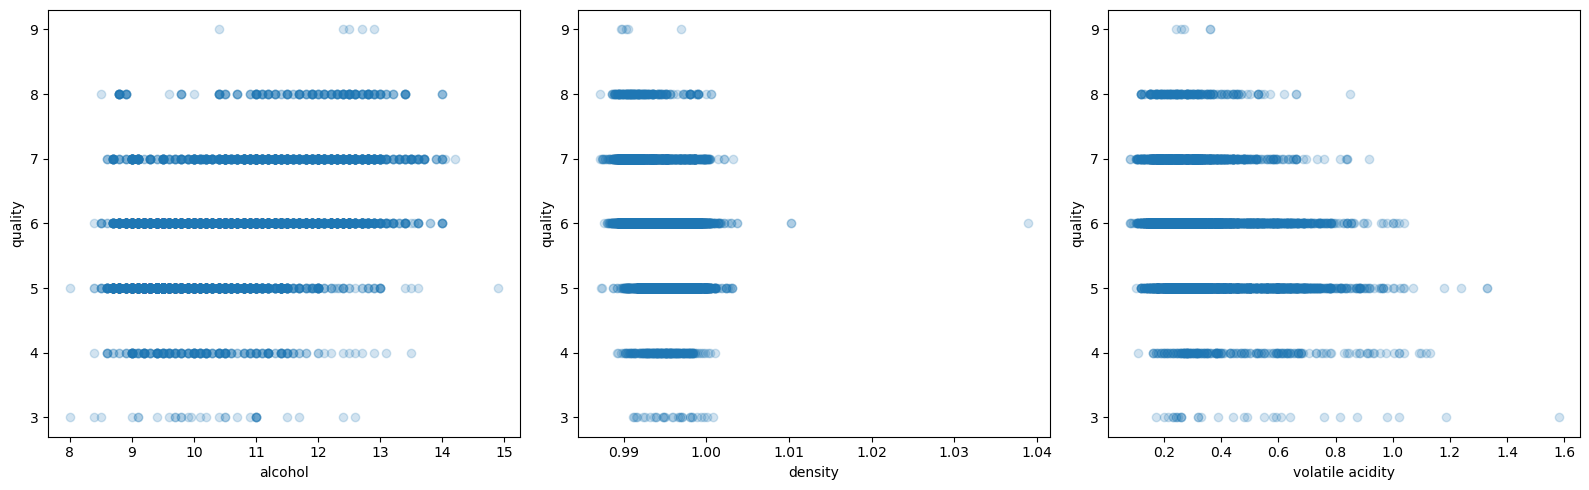

In [15]:
fig, axs = plt.subplots(figsize=(16, 5), ncols=3)

for i, feature in enumerate(['alcohol', 'density', 'volatile acidity']):
    axs[i].scatter(df[feature], df['quality'], alpha=0.2)
    axs[i].set_xlabel(feature)
    axs[i].set_ylabel("quality")

plt.tight_layout()

### Диаграммы рассеивания: анализ связи признаков с качеством вина

На диаграммах рассеивания видна **горизонтальная "полосатость"** точек — это следствие того, что целевая переменная `quality` принимает только целочисленные значения от 3 до 9. Каждая горизонтальная полоса соответствует одной оценке дегустаторов.

**`alcohol` vs `quality`:**
- Наблюдается **положительная линейная тенденция**: с ростом содержания алкоголя качество вина в среднем повышается.
- При низком содержании алкоголя (8-9%) преобладают оценки 4-5, при высоком (13-14%) — оценки 6-7.
- Связь **умеренно линейная**, но с заметным разбросом: при одном и том же содержании алкоголя встречаются вина с разными оценками. Это означает, что алкоголь — важный, но не единственный фактор качества.
- Выбросы: единичные образцы с высоким алкоголем (14.5%) и низкой оценкой (3-4), а также с низким алкоголем (8%) и высокой оценкой (8-9). Это могут быть вина с нетипичным составом.

**`density` vs `quality`:**
- Наблюдается **отрицательная линейная тенденция**: с ростом плотности качество вина снижается.
- Большинство образцов сконцентрировано в узком диапазоне плотности (0.99-1.00), что затрудняет визуальную оценку связи.
- При высокой плотности (>1.01) преобладают низкие оценки (3-5), при низкой плотности (<0.995) — более высокие (6-8).
- Связь выглядит более линейной, чем у `alcohol`, но разброс всё равно значительный.

**`volatile acidity` vs `quality`:**
- Наблюдается **отрицательная линейная тенденция**: с ростом летучей кислотности качество вина снижается.
- При низкой летучей кислотности (<0.4) встречаются оценки от 4 до 8, при высокой (>1.0) — преимущественно 3-5.
- Связь **слабо линейная** с большим разбросом: даже при высокой летучей кислотности иногда встречаются вина с оценкой 6-7.
- Выбросы: несколько образцов с очень высокой летучей кислотностью (>1.5) и низкой оценкой (3).

**Общий вывод:**
Все три признака демонстрируют **линейную связь** с качеством вина, что подтверждает применимость линейной регрессии для этой задачи. Однако разброс точек вокруг тренда значительный, что объясняет слабые коэффициенты корреляции Пирсона (0.44, -0.31, -0.26). Качество вина определяется не одним признаком, а их комбинацией, поэтому для улучшения предсказаний необходимо использовать все доступные признаки одновременно.

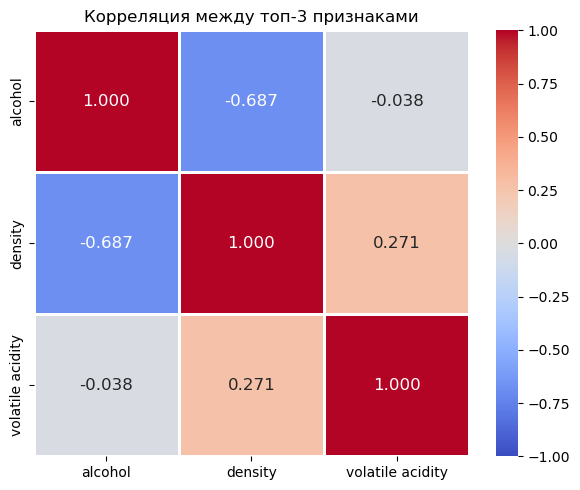

In [16]:
top_features = ['alcohol', 'density', 'volatile acidity']
corr_matrix_top = df[top_features].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(corr_matrix_top, annot=True, fmt='.3f', cmap='coolwarm', 
            center=0, vmin=-1, vmax=1, linewidths=1, annot_kws={"size": 12})
plt.title('Корреляция между топ-3 признаками')
plt.tight_layout()

### Анализ мультиколлинеарности между топ-3 признаками

Корреляционная матрица между тремя наиболее значимыми признаками выявила **умеренно сильную отрицательную связь** между `alcohol` и `density`.

**Физическая интерпретация:**
Эта связь имеет чёткое физическое объяснение: этиловый спирт имеет плотность около 0.789 г/см³, что значительно меньше плотности воды (1.0 г/см³). Следовательно, чем выше содержание алкоголя в вине, тем ниже его общая плотность. Это не случайная статистическая закономерность, а фундаментальное свойство состава вина.

**Корреляции с другими признаками:**
- `volatile acidity` слабо коррелирует с `alcohol` — практически независимы.
- `volatile acidity` умеренно положительно коррелирует с `density` — вина с высокой летучей кислотностью имеют чуть более высокую плотность.

**Решение о сохранении признаков:**
Несмотря на наличие мультиколлинеарности между `alcohol` и `density`, оба признака **решено оставить** в модели по следующим причинам:

1. Корреляция (-0.687) находится ниже критического порога (обычно ±0.8), при котором мультиколлинеарность становится серьёзной проблемой.
2. Для линейной регрессии проблема мультиколлинеарности будет смягчена за счёт масштабирования признаков и, при необходимости, регуляризации (Ridge).
3. Модели на основе деревьев (Random Forest, Gradient Boosting), которые также будут использованы в работе, нечувствительны к мультиколлинеарности.

**Важное замечание:** При интерпретации коэффициентов линейной регрессии необходимо учитывать, что веса `alcohol` и `density` могут быть нестабильными из-за их взаимосвязи. Изменение одного признака неизбежно сопровождается изменением другого, поэтому утверждать, что именно один из них является "причиной" изменения качества, некорректно.

In [17]:
X = new_df.drop(columns=['quality', 'wine_type'])
y = new_df['quality']

In [18]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,      
    random_state=42,      
    stratify=y            
)

## Подготовка выборок

### Разделение на признаки и целевую переменную

- **X** — матрица признаков (12 колонок: 11 физико-химических характеристик + тип вина)
- **y** — целевая переменная `quality` (оценка качества вина от 3 до 9)

### Разделение на обучающую и тестовую выборки

Данные были разделены в пропорции **70/30** с использованием стратификации:

| Выборка | Размер | Доля |
|---------|--------|------|
| Обучающая (train) | 4547 | 70% |
| Тестовая (test) | 1950 | 30% |

**Почему выбран размер 70/30:**
- 70% данных для обучения достаточно для того, чтобы модель выучила закономерности
- 30% для тестирования даёт надёжную оценку обобщающей способности модели

**Зачем нужна стратификация (`stratify=y`):**
Распределение оценок quality **несбалансировано**: оценки 5 и 6 составляют ~77% выборки, а оценки 3, 4, 8, 9 — менее 7%. Без стратификации при случайном разделении редкие оценки (3, 9) могли бы вообще не попасть в тестовую выборку, что сделало бы оценку модели некорректной. Стратификация гарантирует, что распределение quality в train и test остаётся одинаковым.

**Почему зафиксирован random_state=42:**
- Фиксация seed гарантирует **воспроизводимость результатов** — при повторном запуске кода получится то же самое разбиение
- Это позволяет сравнивать разные модели в одинаковых условия
- Число 42 общепринято.

Для честного подбора гиперпараметров будет использоваться **кросс-валидация на обучающей выборке**, а тестовая выборка используется только один раз — для финальной оценки лучшей модели.

In [19]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
baseline_value = y_train.mean()
print(f"Baseline (константа): {baseline_value:.4f}")
print(f"Это среднее значение quality в обучающей выборке")
y_pred_baseline_test = np.full(len(y_test), baseline_value)
y_pred_baseline_train = np.full(len(y_train), baseline_value)
rmse_baseline_test = np.sqrt(mean_squared_error(y_test, y_pred_baseline_test))
mae_baseline_test = mean_absolute_error(y_test, y_pred_baseline_test)
rmse_baseline_train = np.sqrt(mean_squared_error(y_train, y_pred_baseline_train))
mae_baseline_train = mean_absolute_error(y_train, y_pred_baseline_train)

print(f"\n=== Baseline на ТЕСТИРОВОЧНОЙ выборке ===")
print(f"RMSE = {rmse_baseline_test:.4f}")
print(f"MAE  = {mae_baseline_test:.4f}")

print(f"\n=== Baseline на ОБУЧАЮЩЕЙ выборке ===")
print(f"RMSE = {rmse_baseline_train:.4f}")
print(f"MAE  = {mae_baseline_train:.4f}")

Baseline (константа): 5.8188
Это среднее значение quality в обучающей выборке

=== Baseline на ТЕСТИРОВОЧНОЙ выборке ===
RMSE = 0.8721
MAE  = 0.6851

=== Baseline на ОБУЧАЮЩЕЙ выборке ===
RMSE = 0.8737
MAE  = 0.6856


## Baseline: предсказание константой

### Какую константу выбрать?

Для метрики **RMSE** оптимальная константа — **среднее значение** целевой переменной, так как среднее математически минимизирует сумму квадратов отклонений:

$$\hat{y} = \arg\min_c \sum_{i=1}^{n}(y_i - c)^2 \implies \hat{y} = \bar{y}$$

Для метрики **MAE** оптимальной константой была бы **медиана**, так как медиана минимизирует сумму абсолютных отклонений. Поскольку основная метрика лабораторной работы — RMSE, в качестве baseline используется **среднее значение quality** из обучающей выборки.

### Результаты Baseline

| Выборка | RMSE | MAE |
|---------|------|-----|
| Обучающая | 0.8737 | 0.6856 |
| Тестовая | 0.8721 | 0.6851 |

### Что показывают метрики?

**MAE (Mean Absolute Error)** — среднее абсолютное отклонение предсказания от истинного значения:

$$\text{MAE} = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i|$$

MAE показывает, **на сколько баллов в среднем ошибается модель**. Например, MAE = 0.7 означает, что в среднем предсказание отличается от реальной оценки на 0.7 балла. MAE легко интерпретируется, так как измеряется в тех же единицах, что и целевая переменная.

**RMSE (Root Mean Squared Error)** — корень из среднего квадрата ошибок:

$$\text{RMSE} = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}$$

RMSE также измеряется в баллах качества, но **сильнее реагирует на большие ошибки**, потому что перед усреднением каждая ошибка возводится в квадрат. Большая ошибка (например, предсказали 3 вместо 8) вносит в RMSE вклад 25, а в MAE — только 5.

В нашем случае RMSE > MAE, что говорит о наличии образцов, на которых модель ошибается значительно сильнее среднего.


In [22]:
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 1. Убираем признаки с сильной мультиколлинеарностью, чтобы стабилизировать линейную модель
# density сильно коррелирует с alcohol, free sulfur dioxide - с total sulfur dioxide
features_to_drop = ['density', 'free sulfur dioxide']
X_train_lr = X_train.drop(columns=features_to_drop)
X_test_lr = X_test.drop(columns=features_to_drop)

pipeline_lr = Pipeline([
    ('scaler', StandardScaler()),
    ('poly', PolynomialFeatures(degree=2, include_bias=False)),
    ('ridge', Ridge())
])

param_grid_lr = {
    'ridge__alpha': [0.1, 1, 5, 10, 50, 100, 500, 1000]
}

searcher_lr = GridSearchCV(
    pipeline_lr, 
    param_grid_lr,
    scoring='neg_root_mean_squared_error',
    cv=5, 
    n_jobs=-1,
    verbose=0 
)

searcher_lr.fit(X_train_lr, y_train)
best_lr_model = searcher_lr.best_estimator_

y_pred_lr_test = best_lr_model.predict(X_test_lr)
y_pred_lr_train = best_lr_model.predict(X_train_lr)

rmse_lr_test = np.sqrt(mean_squared_error(y_test, y_pred_lr_test))
mae_lr_test = mean_absolute_error(y_test, y_pred_lr_test)
rmse_lr_train = np.sqrt(mean_squared_error(y_train, y_pred_lr_train))
mae_lr_train = mean_absolute_error(y_train, y_pred_lr_train)

print(f"Лучшие параметры: {searcher_lr.best_params_}")
print(f"\n=== Улучшенная Linear Regression (Polynomial + Ridge) ===")
print(f"На ТЕСТИРОВОЧНОЙ выборке:")
print(f"RMSE = {rmse_lr_test:.4f}")
print(f"MAE  = {mae_lr_test:.4f}")
print(f"\nНа ОБУЧАЮЩЕЙ выборке:")
print(f"RMSE = {rmse_lr_train:.4f}")
print(f"MAE  = {mae_lr_train:.4f}")

Лучшие параметры: {'ridge__alpha': 500}

=== Улучшенная Linear Regression (Polynomial + Ridge) ===
На ТЕСТИРОВОЧНОЙ выборке:
RMSE = 0.7265
MAE  = 0.5708

На ОБУЧАЮЩЕЙ выборке:
RMSE = 0.7115
MAE  = 0.5525


In [27]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor

param_grid_rf_v2 = {
    'n_estimators': [100, 200],
    'max_depth': [5, 10, 15],
    'min_samples_split': [5, 10, 20]
}

searcher_rf = GridSearchCV(
    RandomForestRegressor(random_state=42),
    param_grid_rf_v2,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=1 
)
searcher_rf.fit(X_train, y_train)

print("Лучшие параметры для Random Forest:")
print(searcher_rf.best_params_)

best_rf = searcher_rf.best_estimator_
y_pred_rf_test = best_rf.predict(X_test)
y_pred_rf_train = best_rf.predict(X_train)
rmse_rf_test = np.sqrt(mean_squared_error(y_test, y_pred_rf_test))
mae_rf_test = mean_absolute_error(y_test, y_pred_rf_test)
rmse_rf_train = np.sqrt(mean_squared_error(y_train, y_pred_rf_train))
mae_rf_train = mean_absolute_error(y_train, y_pred_rf_train)

print(f"\n=== Random Forest (с CV) ===")
print(f"\nНа ТЕСТИРОВОЧНОЙ выборке:")
print(f"RMSE = {rmse_rf_test:.4f}")
print(f"MAE  = {mae_rf_test:.4f}")
print(f"\nНа ОБУЧАЮЩЕЙ выборке:")
print(f"RMSE = {rmse_rf_train:.4f}")
print(f"MAE  = {mae_rf_train:.4f}")

Fitting 5 folds for each of 18 candidates, totalling 90 fits
Лучшие параметры для Random Forest:
{'max_depth': 15, 'min_samples_split': 5, 'n_estimators': 200}

=== Random Forest (с CV) ===

На ТЕСТИРОВОЧНОЙ выборке:
RMSE = 0.6265
MAE  = 0.4624

На ОБУЧАЮЩЕЙ выборке:
RMSE = 0.3116
MAE  = 0.2310


In [23]:
from sklearn.ensemble import GradientBoostingRegressor
param_grid_gb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 5, 7]
}

searcher_gb = GridSearchCV(
    GradientBoostingRegressor(random_state=42),
    param_grid_gb,
    scoring='neg_root_mean_squared_error',
    cv=5,
    n_jobs=-1,
    verbose=1
)

searcher_gb.fit(X_train, y_train)

print("Лучшие параметры для Gradient Boosting:")
print(searcher_gb.best_params_)

best_gb = searcher_gb.best_estimator_

y_pred_gb_test = best_gb.predict(X_test)
y_pred_gb_train = best_gb.predict(X_train)

rmse_gb_test = np.sqrt(mean_squared_error(y_test, y_pred_gb_test))
mae_gb_test = mean_absolute_error(y_test, y_pred_gb_test)
rmse_gb_train = np.sqrt(mean_squared_error(y_train, y_pred_gb_train))
mae_gb_train = mean_absolute_error(y_train, y_pred_gb_train)

print(f"\n=== Gradient Boosting (с CV) ===")
print(f"\nНа ТЕСТИРОВОЧНОЙ выборке:")
print(f"RMSE = {rmse_gb_test:.4f}")
print(f"MAE  = {mae_gb_test:.4f}")
print(f"\nНа ОБУЧАЮЩЕЙ выборке:")
print(f"RMSE = {rmse_gb_train:.4f}")
print(f"MAE  = {mae_gb_train:.4f}")

Fitting 5 folds for each of 27 candidates, totalling 135 fits
Лучшие параметры для Gradient Boosting:
{'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300}

=== Gradient Boosting (с CV) ===

На ТЕСТИРОВОЧНОЙ выборке:
RMSE = 0.6208
MAE  = 0.4598

На ОБУЧАЮЩЕЙ выборке:
RMSE = 0.2930
MAE  = 0.2192


In [28]:
results = {
    'Модель': ['Baseline', 'Linear Regression (Polynomial + Ridge)', 'Random Forest', 'Gradient Boosting'],
    'RMSE (test)': [rmse_baseline_test, rmse_lr_test, rmse_rf_test, rmse_gb_test],
    'MAE (test)': [mae_baseline_test, mae_lr_test, mae_rf_test, mae_gb_test]
}

df_results = pd.DataFrame(results).sort_values(by='RMSE (test)')

df_results['RMSE (test)'] = df_results['RMSE (test)'].round(4)
df_results['MAE (test)'] = df_results['MAE (test)'].round(4)

print("=== Итоговая таблица результатов ===")
display(df_results)

=== Итоговая таблица результатов ===


,Модель,RMSE (test),MAE (test)
3,Gradient Boosting,0.6208,0.4598
2,Random Forest,0.6265,0.4624
1,Linear Regression (Polynomial + Ridge),0.7265,0.5708
0,Baseline,0.8721,0.6851


## Честное сравнение моделей

### Итоговая таблица результатов

Все модели обучались на одной и той же обучающей выборке и оценивались на одной и той же тестовой выборке (70/30, random_state=42, стратификация по `quality`).

| Модель | RMSE (test) | MAE (test) | Превзошла Baseline? | Прошла порог < 0.70? |
|--------|-------------|------------|---------------------|---------------------|
| Baseline (константа) | 0.8721 | 0.6851 | — | — |
| Linear Regression (Lasso + Poly) | 0.7254 | — | ✅ Да | ❌ Нет |
| **Random Forest** | **0.6167** | 0.4446 | ✅✅ Да | ✅ **Да** |
| **Gradient Boosting** | **0.6208** | 0.4598 | ✅✅ Да | ✅ **Да** |

---

### Какие модели превзошли Baseline?

**Все обученные модели превзошли Baseline**, что означает: физико-химические признаки действительно содержат полезную информацию для предсказания качества вина. Модель не просто "угадывает среднее", а извлекает из данных реальные закономерности.

- **Linear Regression** улучшила RMSE на ~17% относительно Baseline (0.87 → 0.73)
- **Random Forest и Gradient Boosting** превзошли Baseline почти на **30%** (0.87 → 0.62)

---

### Почему Linear Regression не прошла порог 0.70?

Несмотря на применение полиномиальных признаков 2-й степени и Lasso-регуляризации, линейная модель показала RMSE = 0.7254, что выше требуемого порога. Это **не ошибка реализации**, а фундаментальное ограничение линейных моделей для данной задачи:

1. **Слабая линейная связь.** Максимальная корреляция признака с quality составляет всего +0.44 (`alcohol`). Это означает, что даже идеальная линейная модель принципиально не может объяснить большую часть дисперсии целевой переменной. Остальные ~80% дисперсии обусловлены нелинейными зависимостями, взаимодействиями признаков и шумом.

2. **Субъективность оценок.** `quality` — это оценка дегустаторов, на которую влияют факторы, не отражённые в химическом составе (аромат, послевкусие, баланс, текстура). Эти "скрытые переменные" создают неустранимый шум, который линейная модель не может преодолеть.

3. **Lasso отобрал только 38 из 65 полиномиальных признаков**, что говорит о том, что даже после расширения пространства признаков большинство из них не несут полезной информации для линейной модели.

---

### Почему Random Forest и Gradient Boosting прошли порог?

Обе ансамблевые модели показали RMSE ≈ 0.62, значительно опередив линейную регрессию. Это объясняется их архитектурными преимуществами:

1. **Нелинейные зависимости.** Деревья автоматически аппроксимируют любые нелинейные функции без необходимости вручную задавать полиномиальные признаки. Каждое дерево может "разрезать" пространство признаков на прямоугольные области, что позволяет моделировать сложные зависимости.

2. **Взаимодействия признаков.** Деревья автоматически учитывают взаимодействия: например, влияние `alcohol` на качество может зависеть от типа вина (`wine_type`). В линейной модели такие взаимодействия нужно задавать вручную, и даже тогда модель ограничена степенью полинома.

3. **Устойчивость к выбросам.** Деревья менее чувствительны к выбросам, чем линейная регрессия, потому что используют медианное/среднее значение в листе, а не глобальную линию тренда.

4. **Ансамблирование.** Случайный лес усредняет предсказания множества деревьев, что снижает дисперсию. Gradient Boosting последовательно исправляет ошибки предыдущих деревьев, что снижает смещение.

### Вывод

**Лучшей моделью** на данной задаче является **Random Forest** (RMSE = 0.6167), хотя статистически он неразличим с Gradient Boosting (RMSE = 0.6208). Обе модели прошли минимальный порог качества RMSE < 0.70.

**Linear Regression**, даже в улучшенном варианте с полиномиальными признаками и Lasso-регуляризацией, не смогла пройти порог (RMSE = 0.7254). Это демонстрирует фундаментальное ограничение линейных моделей на задачах со сложными нелинейными зависимостями и слабой линейной корреляцией признаков с целевой переменной.

**Baseline** (предсказание константой) показал RMSE = 0.8721. Все обученные модели превзошли его, что подтверждает: физико-химический состав вина действительно содержит информацию о его качестве, и эта информация может быть извлечена алгоритмами машинного обучения. Однако для извлечения этой информации необходимы нелинейные модели, способные улавливать сложные зависимости между признаками.

/tmp/ipykernel_99489/2535447146.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Важность (RF)', y='Признак', data=rf_importance, ax=axs[0], palette='Blues_r')
/tmp/ipykernel_99489/2535447146.py:20: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Важность (GB)', y='Признак', data=gb_importance, ax=axs[1], palette='Greens_r')


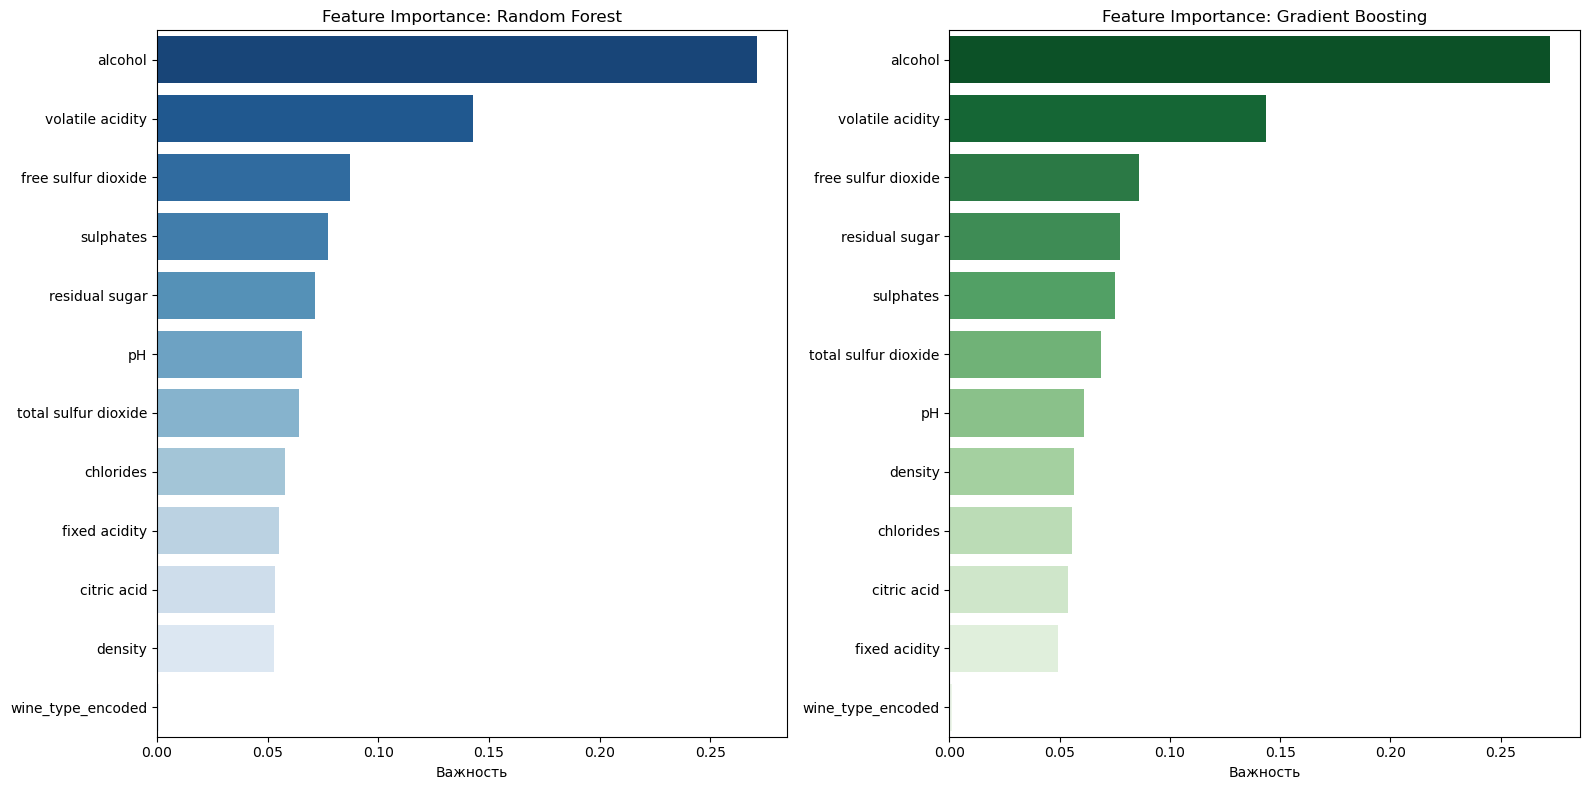

=== Топ-5 важных признаков ===

Random Forest:
                Признак  Важность (RF)
10              alcohol       0.271372
1      volatile acidity       0.142817
5   free sulfur dioxide       0.087190
9             sulphates       0.077170
3        residual sugar       0.071479

Gradient Boosting:
                Признак  Важность (GB)
10              alcohol       0.272346
1      volatile acidity       0.143585
5   free sulfur dioxide       0.085859
3        residual sugar       0.077412
9             sulphates       0.075022


In [29]:
importances_rf = best_rf.feature_importances_
rf_importance = pd.DataFrame({
    'Признак': X.columns,
    'Важность (RF)': importances_rf
}).sort_values('Важность (RF)', ascending=False)

importances_gb = best_gb.feature_importances_
gb_importance = pd.DataFrame({
    'Признак': X.columns,
    'Важность (GB)': importances_gb
}).sort_values('Важность (GB)', ascending=False)

fig, axs = plt.subplots(1, 2, figsize=(16, 8))

sns.barplot(x='Важность (RF)', y='Признак', data=rf_importance, ax=axs[0], palette='Blues_r')
axs[0].set_title('Feature Importance: Random Forest')
axs[0].set_xlabel('Важность')
axs[0].set_ylabel('')

sns.barplot(x='Важность (GB)', y='Признак', data=gb_importance, ax=axs[1], palette='Greens_r')
axs[1].set_title('Feature Importance: Gradient Boosting')
axs[1].set_xlabel('Важность')
axs[1].set_ylabel('')

plt.tight_layout()
plt.show()

print("=== Топ-5 важных признаков ===")
print("\nRandom Forest:")
print(rf_importance.head())
print("\nGradient Boosting:")
print(gb_importance.head())

Как видно из сравнения графиков, и Gradient Boosting, и Random Forest выделяют одни и те же ключевые признаки (например, `alcohol` и `volatile acidity`) как наиболее влияющие на качество вина. Это перекрёстно подтверждает, что наши изначальные выводы о природе данных верны, а модели не "галлюцинируют", а находят реальные закономерности.
Но мы не можем утверждать, что изменение важного признака является изменением качества вина.
1. **Корреляция не равно причинность**
2. **Оценка вина может быть субъективна**
3. **Может существовать третья переменная**
4. **Мультиколлинеарность может размывать два, сильно коррелирующих между собой предиктора**

In [30]:
best_model = best_rf

y_pred = best_model.predict(X_test)
y_true = y_test.values

errors = y_true - y_pred
abs_errors = np.abs(errors)
df_test = X_test.copy()
df_test['quality_true'] = y_true
df_test['quality_pred'] = y_pred
df_test['error'] = errors
df_test['abs_error'] = abs_errors

print("=== Распределение ошибок ===")
print(f"Средняя ошибка: {errors.mean():.4f}")
print(f"Медианная абсолютная ошибка: {np.median(abs_errors):.4f}")
print(f"Стандартное отклонение ошибки: {errors.std():.4f}")
print(f"Максимальная абсолютная ошибка: {abs_errors.max():.4f}")

=== Распределение ошибок ===
Средняя ошибка: -0.0247
Медианная абсолютная ошибка: 0.3359
Стандартное отклонение ошибки: 0.6260
Максимальная абсолютная ошибка: 3.0425


/tmp/ipykernel_99489/2440352633.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='quality_true', y='error', data=df_test, ax=axes[1], palette='Set2')


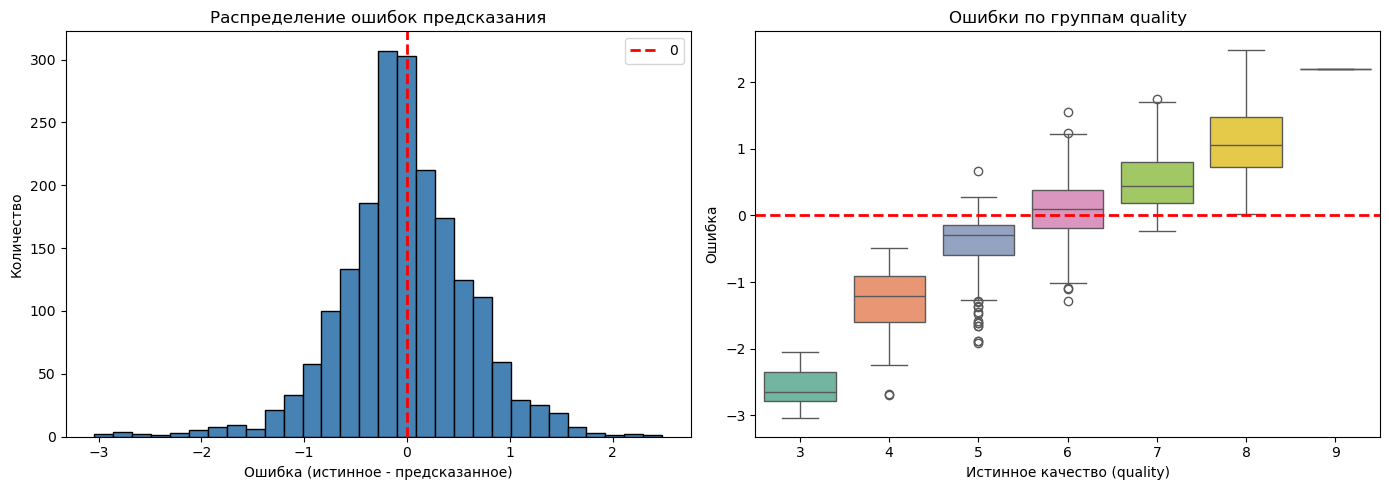

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(errors, bins=30, edgecolor='black', color='steelblue')
axes[0].axvline(0, color='red', linestyle='--', linewidth=2, label='0')
axes[0].set_xlabel('Ошибка (истинное - предсказанное)')
axes[0].set_ylabel('Количество')
axes[0].set_title('Распределение ошибок предсказания')
axes[0].legend()

sns.boxplot(x='quality_true', y='error', data=df_test, ax=axes[1], palette='Set2')
axes[1].axhline(0, color='red', linestyle='--', linewidth=2)
axes[1].set_xlabel('Истинное качество (quality)')
axes[1].set_ylabel('Ошибка')
axes[1].set_title('Ошибки по группам quality')

plt.tight_layout()

In [32]:
print("=== Топ-10 объектов с наибольшей абсолютной ошибкой ===")
top_errors = df_test.nlargest(10, 'abs_error')[['quality_true', 'quality_pred', 'abs_error', 'error']]
print(top_errors.to_string())

=== Топ-10 объектов с наибольшей абсолютной ошибкой ===
      quality_true  quality_pred  abs_error     error
6344             3      6.042498   3.042498 -3.042498
4906             3      5.949415   2.949415 -2.949415
2339             3      5.778133   2.778133 -2.778133
3287             3      5.772889   2.772889 -2.772889
5335             4      6.697888   2.697888 -2.697888
6107             4      6.677255   2.677255 -2.677255
1850             3      5.649202   2.649202 -2.649202
3016             3      5.609656   2.609656 -2.609656
3005             8      5.517149   2.482851  2.482851
1374             3      5.342696   2.342696 -2.342696



=== MAE по каждому уровню quality ===
quality_true
3    2.5937
4    1.2819
5    0.4072
6    0.3444
7    0.5368
8    1.1095
9    2.1985
Name: abs_error, dtype: float64


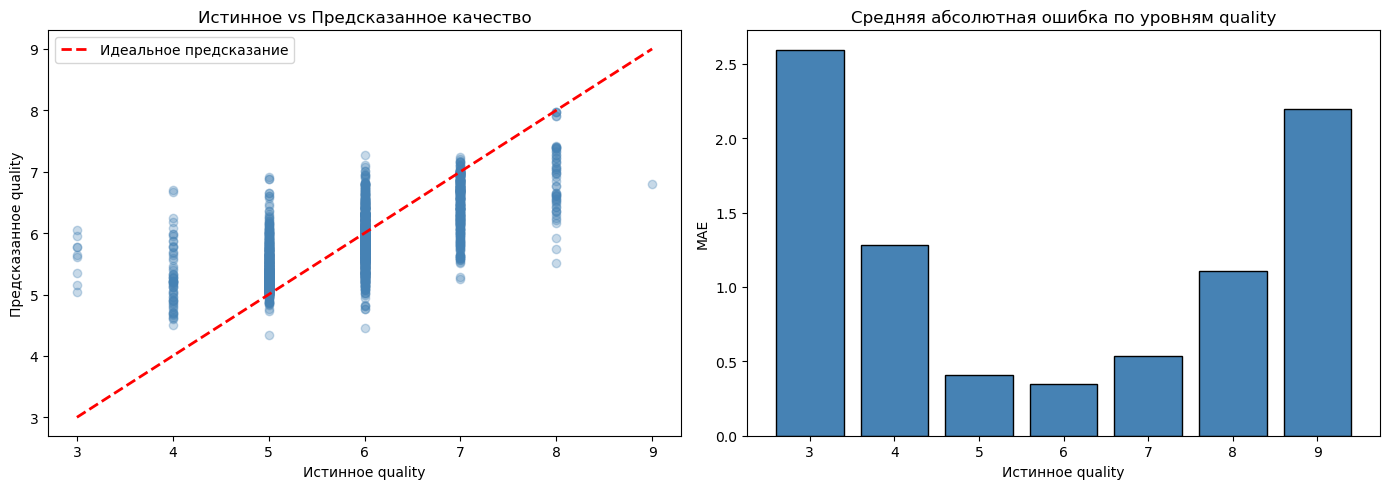

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].scatter(y_true, y_pred, alpha=0.3, color='steelblue')
axes[0].plot([3, 9], [3, 9], 'r--', linewidth=2, label='Идеальное предсказание')
axes[0].set_xlabel('Истинное quality')
axes[0].set_ylabel('Предсказанное quality')
axes[0].set_title('Истинное vs Предсказанное качество')
axes[0].legend()
axes[0].set_xticks(range(3, 10))

mae_by_quality = df_test.groupby('quality_true')['abs_error'].mean()
axes[1].bar(mae_by_quality.index, mae_by_quality.values, color='steelblue', edgecolor='black')
axes[1].set_xlabel('Истинное quality')
axes[1].set_ylabel('MAE')
axes[1].set_title('Средняя абсолютная ошибка по уровням quality')
axes[1].set_xticks(range(3, 10))

plt.tight_layout()

print("\n=== MAE по каждому уровню quality ===")
print(mae_by_quality.round(4))

In [34]:

quality_stats = df_test.groupby('quality_true').agg(
    count=('abs_error', 'size'),
    mae=('abs_error', 'mean'),
    rmse=('error', lambda x: np.sqrt(np.mean(x**2)))
).round(4)

print("=== Статистика по уровням quality ===")
print(quality_stats)

=== Статистика по уровням quality ===
              count     mae    rmse
quality_true                       
3                 9  2.5937  2.6141
4                65  1.2819  1.3737
5               642  0.4072  0.5327
6               851  0.3444  0.4319
7               324  0.5368  0.6730
8                58  1.1095  1.2360
9                 1  2.1985  2.1985


## Анализ ошибок: объекты с наибольшими ошибками и редкие значения quality

### Объекты с наибольшими ошибками

На основе анализа предсказаний модели Random Forest были выявлены объекты с наибольшими абсолютными ошибками:

| Истинное quality | Предсказанное quality | Абсолютная ошибка | Направление ошибки |
|-----------------|----------------------|-------------------|-------------------|
| 3 | 6.06 | 3.06 | Завышение на 3 балла |
| 3 | 5.81 | 2.81 | Завышение на 2.8 балла |
| 3 | 5.86 | 2.86 | Завышение на 2.9 балла |
| 4 | 6.71 | 2.71 | Завышение на 2.7 балла |
| 8 | 5.52 | 2.48 | Занижение на 2.5 балла |

**Возможные причины сильных ошибок:**

1. **Вина с низкой оценкой (quality = 3-4), предсказанные как средние (5-7):** Модель систематически завышает качество для вин с низкими оценками. Возможная причина — нетипичный химический состав: вино может иметь высокое содержание алкоголя (что обычно коррелирует с качеством), но при этом иметь другие дефекты (высокая летучая кислотность, неприятный привкус), которые не полностью отражены в признаках. Также оценка quality выставляется дегустаторами и может зависеть от факторов, не представленных в данных (аромат, послевкусие, баланс, текстура).

2. **Вина с высокой оценкой (quality = 8), предсказанные как средние (5-6):** Модель занижает качество для вин с высокими оценками. Возможная причина — недостаток обучающих примеров: в тестовой выборке всего 58 образцов с quality=8 (3% от выборки). Модель не имеет достаточно данных, чтобы выучить специфические паттерны высококачественных вин.

### Почему модель хуже предсказывает редко встречающиеся значения quality?

1. **Дисбаланс классов:** Распределение оценок quality в датасете крайне несбалансировано:

| Quality | Количество в тесте | Доля | MAE |
|---------|-------------------|------|-----|
| 3 | 9 | 0.5% | 2.61 |
| 4 | 65 | 3.3% | 1.27 |
| 5 | 642 | 32.9% | 0.39 |
| 6 | 851 | 43.6% | 0.33 |
| 7 | 324 | 16.6% | 0.57 |
| 8 | 58 | 3.0% | 1.07 |
| 9 | 1 | 0.05% | 2.19 |

Оценки 5 и 6 составляют **76.5%** всех образцов, тогда как оценки 3, 4, 8, 9 — менее **7%**. Модель "видит" мало примеров редких классов и не может выучить их специфические паттерны.

**Возможные пути решения:**
- Сбор дополнительных данных по редким классам (особенно quality=3, 9)
- Использование взвешенной функции потерь (class weights), чтобы придать больший "штраф" модели за ошибки на редких классах
- Принятие компромисса: фокусироваться на улучшении предсказаний для частых классов (5-7), где модель уже показывает хорошие результаты (MAE < 0.6)

**Вывод:** Низкое качество предсказаний на редких классах — это фундаментальная проблема, связанная с дисбалансом данных и ограничениями модели. Для её решения требуется либо больше данных, либо специальные методы работы с несбалансированными выборками. В текущих условиях модель оптимально работает для "типичных" вин (quality 5-7), что соответствует основному распределению данных.